# Part 1: Import Packages

In [1]:
%pip install ucimlrepo scikit-optimize

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.calibration import CalibratedClassifierCV

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import CalibrationDisplay
from sklearn.frozen import FrozenEstimator
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

To ensure our experiment is reproducible, we will set a single seed (42) to be used throughout the training.

In [2]:
SEED = 42

# Part 2: Importing Dataset

The dataset was loaded from the UCI repository as a feature table plus a target column. From [UCI](#https://archive.ics.uci.edu/dataset/94/spambase), Spambase has 4,601 rows and 57 numeric features, with no missing values.

In [3]:
# fetch spam dataset
spambase = fetch_ucirepo(id=94)
spam_df = pd.concat((spambase.data.features, spambase.data.targets), axis=1)

# variable information
print(spambase.variables)

                          name     role        type demographic  \
0               word_freq_make  Feature  Continuous        None   
1            word_freq_address  Feature  Continuous        None   
2                word_freq_all  Feature  Continuous        None   
3                 word_freq_3d  Feature  Continuous        None   
4                word_freq_our  Feature  Continuous        None   
5               word_freq_over  Feature  Continuous        None   
6             word_freq_remove  Feature  Continuous        None   
7           word_freq_internet  Feature  Continuous        None   
8              word_freq_order  Feature  Continuous        None   
9               word_freq_mail  Feature  Continuous        None   
10           word_freq_receive  Feature  Continuous        None   
11              word_freq_will  Feature  Continuous        None   
12            word_freq_people  Feature  Continuous        None   
13            word_freq_report  Feature  Continuous        Non

In [4]:
# See the first 5 spam samples
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [5]:
# See data types in each column
spam_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

In [6]:
# Check if there are any duplicate rows in the dataset
spam_df[spam_df.duplicated(keep=False)]

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
24,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4441,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4537,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,6,0
4541,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,2,0


## 2.1. Grouping

In real scenarios, spam messages often have the same exact information, so duplicate samples also serve as a signal of repeating events. Thus, instead of simply removing them, we will group the duplicates and giving unique samples with unique ids.

In [7]:
spam_feature_cols = [col for col in spam_df.columns if col != 'Class']
X_spam, y_spam = spam_df[spam_feature_cols], spam_df['Class']

# Check class balance
print(f"Original Balance: {y_spam.mean():.2%} spam")

# Creating group ids (identical rows share the same id)
groups = spam_df.groupby(spam_feature_cols).ngroup()
print(f"{len(spam_df)} samples --> {groups.max() + 1} groups")

# Count identical rows with conflicting labels
conflicts = spam_df.groupby(groups)['Class'].nunique().gt(1).sum()
print(f"Groups with conflicting labels: {conflicts}")

Original Balance: 39.40% spam
4601 samples --> 4207 groups
Groups with conflicting labels: 3


## 2.2. Splitting

Due to the class imbalance, we want to use a stratified split. Since we also want to split the **duplicate-grouped** dataset into training, calibration, validation, and testing sets, we will use `StrateifiedGroupKFold` to satisfy all of these criterions.

In [8]:
# 10 stratified folds that never split a group
fold = np.empty(len(spam_df), dtype=int)
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
for k, (_, idx) in enumerate(sgkf.split(X_spam, y_spam, groups)):
    fold[idx] = k

# Split 40% train, 30% calibration pool, 10% validation, 20% test
part = np.select([fold < 4, fold < 7, fold < 8], ['train', 'cal', 'val'], 'test')

# Select rows from X_spam that correspond to rows in `part` that are labelled as 'train'
X_spam_train, y_spam_train = X_spam[part == 'train'], y_spam[part == 'train']

X_spam_cal,   y_spam_cal   = X_spam[part == 'cal'],   y_spam[part == 'cal']
X_spam_val,   y_spam_val   = X_spam[part == 'val'],   y_spam[part == 'val']
X_spam_test,  y_spam_test  = X_spam[part == 'test'],  y_spam[part == 'test']

# Check every group belongs to exactly one set, and class balance is preserved
assert (pd.Series(part).groupby(groups.values).nunique() == 1).all()
print(pd.Series(y_spam.values).groupby(part).agg(['size', 'mean']))

       size      mean
cal    1404  0.397436
test    955  0.392670
train  1791  0.392518
val     451  0.392461


# Part 3: Baseline Modeling

## 3.1. Custom Functions

### 3.1.1. Estimator Pipeline

Preprocessing (one-hot encoding and scaling) is wrapped in a `Pipeline` with the classifier. During cross-validation, the encoder and scaler are refit on each training fold only, so no information from the validation fold leaks into preprocessing.

<u>Idea:</u> Automatically perform `.fit_transform()` on the training set and `.transform()` on the held-out data during preprocessing.

In [9]:
def create_pipeline(model, categorical_features, numerical_features, drop=None):
    # Set up column transformer to encode categorical features and
    # scale numerical features
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', drop=drop), categorical_features),
            ('num', StandardScaler(), numerical_features)
        ],
        remainder='passthrough',
        force_int_remainder_cols=False
    )
    # Set up pipeline with column transformer and inputted model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    return pipeline

### 3.1.2. Score Function

Compute the Brier and Log-Loss scores of the model, as well as its expected cost, to evaluate the model's performance.

In [10]:
def score(model, X, y, c_fp, c_fn):
    threshold = c_fp / (c_fp + c_fn)
    p = model.predict_proba(X)[:, 1]
    pred = p > threshold
    cost = (c_fp * np.sum(pred & (y == 0)) + c_fn * np.sum(~pred & (y == 1))) / len(y)
    return brier_score_loss(y, p), log_loss(y, p), cost

## 3.2 Model Training

For the baseline, we will tune the hyperparameter `C` of the Logistic Regression model on the stratified 5-fold CV on the **training set** (`X_spam_train`, `y_spam_train`). We then draw a **reliability diagram** of the model evaluated on the **validation set** (`X_spam_val`, `y_spam_val`).

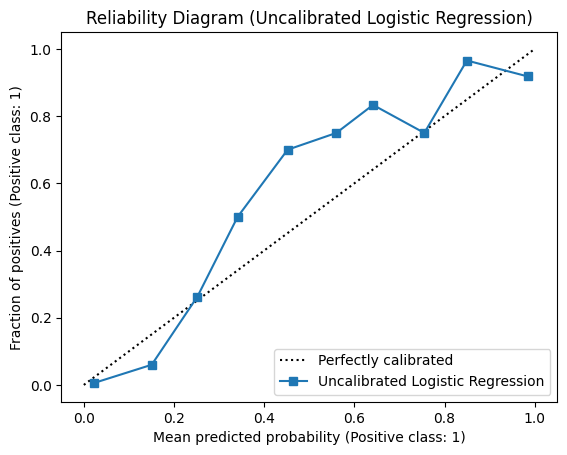

In [11]:
# Tune and train the logistic regression model on training data
train_group = groups[part == 'train']
cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X_spam_train, y_spam_train, train_group))

spam_lr = create_pipeline(LogisticRegressionCV(Cs=np.logspace(-3, 2, 11), cv=cv, scoring='neg_log_loss',
                                               max_iter=2000, random_state=SEED), [], spam_feature_cols)
spam_lr.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_lr, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Logistic Regression")
plt.title("Reliability Diagram (Uncalibrated Logistic Regression)")
plt.show()

For the baseline, we will fit an untuned Random Forest on the training set and draw a reliability diagram on the validation set.

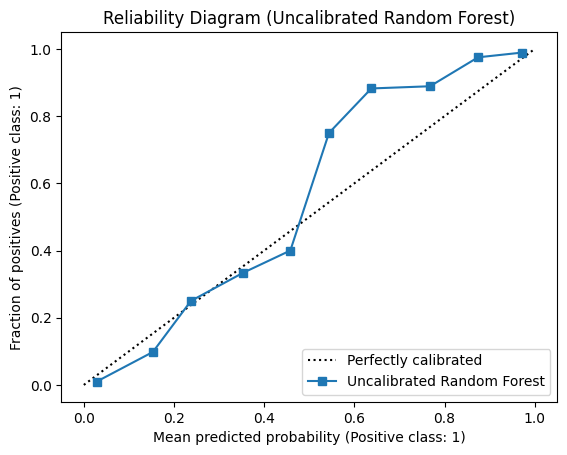

In [12]:
# Train the Random Forest model on training data
spam_rf = create_pipeline(RandomForestClassifier(random_state=SEED), [], spam_feature_cols)
spam_rf.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_rf, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Random Forest")
plt.title("Reliability Diagram (Uncalibrated Random Forest)")
plt.show()

## 3.3. Model Calibration

Missing a spam email (**FN**) is not as costly as missing real, potentially important email (**FP**), so we want to set the cost of a false positive to be **greater** than the cost of a false negative.

In this section, we will calibrate the fitted (untuned) Logistic Regression and Random Forest. For each model, we will randomly draw 100 samples from the **calibration set** (`X_spam_cal`, `y_spam_cal`) and fit Platt (`sigmoid`) and `isotonic` calibration on the model. We then compute the Brier and Los-Loss scores, as well as the expected cost, for each of the calibration types on the **validation set**, (`X_spam_val`, `y_spam_val`) using the `score()` function. We will repeatedly this process 50 times. Then we will repeat all of these for drawing 1,000 samples from the calibration set.

**Note**: `CalibratedClassifierCV` normally clones the inputted model and refit the clone on the calibration set. However, cloning the model will delete the learned weights fitted from the **training set**, essentially training the models from scratch on the calibration set. Thus, we will use `FrozenEstimator` to force the calibrator to keep the original model's learned weight and use the calibration set strictly for learning the probability adjustments.

**Note**: `n=0` is the uncalibrated model

In [13]:
# Arbitrary costs
C_FP, C_FN = 5, 1

rng = np.random.default_rng(SEED)
rows = []
for name, model in {'LR': spam_lr, 'RF': spam_rf}.items():
    rows.append((name, 'none', 0, *score(model, X_spam_val, y_spam_val, C_FP, C_FN)))
    for n in (100, 1000):
        for _ in range(50):
            idx = rng.choice(len(y_spam_cal), n, replace=False)
            for method in ('sigmoid', 'isotonic'):
                cal = CalibratedClassifierCV(FrozenEstimator(model), method=method)
                cal.fit(X_spam_cal.iloc[idx], y_spam_cal.iloc[idx])
                rows.append((name, method, n, *score(cal, X_spam_val, y_spam_val, C_FP, C_FN)))

cal_result = pd.DataFrame(rows, columns=['model', 'method', 'n', 'brier', 'logloss', 'cost'])
print(cal_result.groupby(['model', 'method', 'n']).agg(['mean', 'std']).round(4))

                      brier         logloss            cost        
                       mean     std    mean     std    mean     std
model method   n                                                   
LR    isotonic 100   0.0694  0.0059  0.7155  0.4038  0.2483  0.0335
               1000  0.0654  0.0009  0.2290  0.0104  0.2250  0.0152
      none     0     0.0665     NaN  0.2790     NaN  0.2373     NaN
      sigmoid  100   0.0837  0.0188  0.2975  0.0419  0.2874  0.0298
               1000  0.0759  0.0022  0.2765  0.0027  0.2866  0.0072
RF    isotonic 100   0.0541  0.0049  0.7570  0.4155  0.1249  0.0197
               1000  0.0500  0.0010  0.1827  0.0175  0.1236  0.0060
      none     0     0.0509     NaN  0.1857     NaN  0.1197     NaN
      sigmoid  100   0.0504  0.0037  0.1858  0.0137  0.1255  0.0178
               1000  0.0489  0.0005  0.1774  0.0022  0.1194  0.0020


## 3.4. Plotting Costs

We will then generate a plot with error bars to visualize how different calibration set sizes impact the validation cost of the Logistic Regression model compared to its uncalibrated baseline.

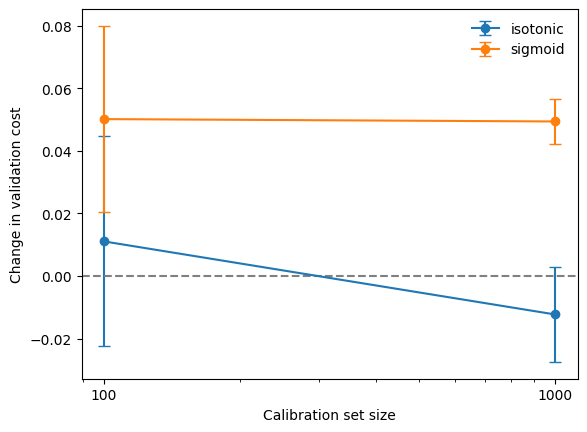

In [14]:
# Plot: change in validation cost vs calibration size (LR)
cal_lr = cal_result[cal_result.model == 'LR']
base_cost = cal_lr.query("method == 'none'").cost.iloc[0]
delta_cost = (cal_lr.query("n > 0").assign(delta=lambda r: r.cost - base_cost)
            .groupby(['method', 'n']).delta.agg(['mean', 'std']).reset_index())

for method, delta in delta_cost.groupby('method'):
    plt.errorbar(delta.n, delta['mean'], delta['std'], marker='o', capsize=4, label=method)

plt.axhline(0, ls='--', c='gray')
plt.xscale('log')
plt.xticks([100, 1000], [100, 1000])
plt.xlabel('Calibration set size')
plt.ylabel('Change in validation cost')
plt.legend(frameon=False)
plt.show()

For Platt scaling (`sigmoid`), the mean and the variation of the change in cost consistently stay positive for both sample sizes (`100` and `1,000`). This indicates that Platt scaling **increases** the expected cost compared to the *uncalibrated* baseline. Logistic Regression optimized the Log-Loss during training using a sigmoid function. Hence, fitting a Platt calibration on it is essentially fitting a sigmoid curve on an optimized-sigmoid curve, introducing noise and polluting the probabilities.

For a small sample size (`100`), `isotonic` calibration has a positive mean change in cost, indicating an **increase** in expected cost. This is because Isotonic regression is a **non-parametric** method that is prone to overfitting when the data is scarce.

However, for a large sample size (`1,000`), `isotonic` calibration has the mean and variation in the negative, indicating thta istonic regression calibration **decreases** the expected cost compared to the *uncalibrated* baseline. A larger dataset can offset the noise, correcting minor non-linear distortions without overfitting.